# Ornstein-Uhlenbeck process

$$dX_t=\kappa(\theta-X_t)\,dt+\sigma\,dB_t^P,$$
with $\kappa=0.5$, $\theta=0$, $\sigma=0.3$, and $X_0=1$.
Use $N=100000$, $T=1$, and seed 3, matching the scale of the earlier experiments.

Compare Method 1, Method 2, and ODE2. The initial drift $\mu(X_0)=-0.5$ is
supplied to every method. ODE2 also uses the known initial slope $-\kappa$.
Its result is conditional on this information, not an independent estimate of $\kappa$.


In [1]:
from pathlib import Path
import os
import sys

roots = [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]
PROJECT_ROOT = next((p for p in roots if (p / 'models/stochastic_sindy.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the SSISDE checkout first. On Colab, download it with the Black-Scholes setup cell.')
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'experiments/ou')
RESULTS = PROJECT_ROOT / 'outputs/ou'
RESULTS.mkdir(parents=True, exist_ok=True)


In [2]:
%pip install -q -r ../../requirements.txt



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pysindy as ps
from sklearn import linear_model
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
from tqdm import tqdm
import iisignature

from models.diffusion_tuning import diffusion_model, fit_diffusion

from threadpoolctl import threadpool_limits
from models.polynomial_diffusion import diffusion_derivatives
from models.noise_recovery import recover_noise


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


## Simulate $X$

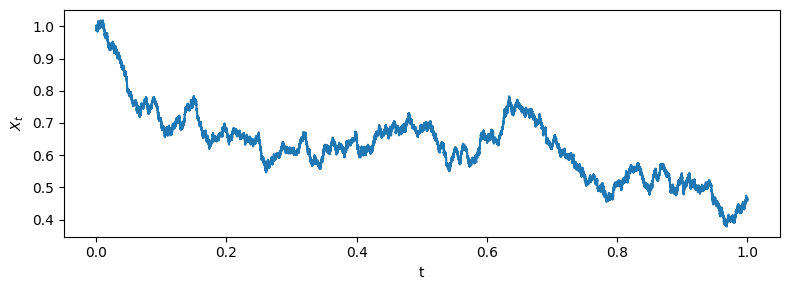

In [4]:
%run -i ../../data_generation/ou.py

plt.figure(figsize=(8, 3))
plt.plot(t, S_)
plt.xlabel('t')
plt.ylabel(r'$X_t$')
plt.tight_layout()
plt.savefig('path.png', dpi=200)
plt.show()


## Estimate $\sigma$

Select SR3 settings on the final 20% of the observed trajectory. The true
diffusion is used only to report error. Quadratic variation and Brownian samples
are aligned with the state samples. Derivatives come from the fitted polynomial,
so a constant diffusion has exactly zero derivatives.


In [5]:
%run -i ../../models/quadratic_variation_cumulative.py


In [6]:
thresholds = [0.1, 0.3, 1.0, 3.0]
nus = [0.1, 0.5, 2.0]
model, sigma_settings, sigma_search = fit_diffusion(S_, t, dQV, thresholds, nus)
diffusion_coefficients = model.coefficients()[0].copy()
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1))).ravel()
sigma_equation = model.equations(precision=8)[0]
print('sigma^2(X) =', sigma_equation)
print(f"threshold = {sigma_settings['threshold']}, nu = {sigma_settings['nu']}")
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))


sigma^2(X) = 0.08941567 1
threshold = 3.0, nu = 2.0


2013

Diffusion RMSE: 0.000975463


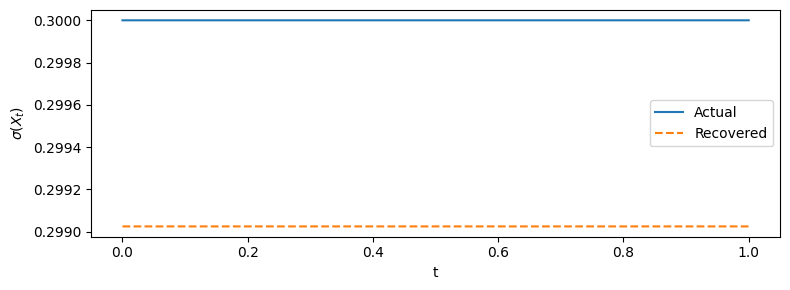

In [7]:
sigma_rmse = float(np.sqrt(np.mean((sigma_pred_ - sigma_exact_)**2)))
print(f'Diffusion RMSE: {sigma_rmse:.6g}')

plt.figure(figsize=(8, 3))
plt.plot(t, sigma_exact_, label='Actual')
plt.plot(t, sigma_pred_, '--', label='Recovered')
plt.xlabel('t')
plt.ylabel(r'$\sigma(X_t)$')
plt.legend()
plt.tight_layout()
plt.savefig('diffusion.png', dpi=200)
plt.show()


## Recover $B^Q$ and estimate $\psi_{21}$

In [8]:
%run -i ../../models/q_brownian_motion.py

keep_cols = [0, 1, 3, 4, 5, 13]
%run -i ../../models/signature_regression.py
%run -i ../../data_generation/coarse_graining.py

sigma_prime, sigma_2prime, sigma_3prime = diffusion_derivatives(diffusion_coefficients, S)


  0%|          | 0/1000 [00:00<?, ?it/s]

 14%|█▍        | 140/1000 [00:00<00:00, 1396.96it/s]

 34%|███▍      | 338/1000 [00:00<00:00, 1736.09it/s]

 55%|█████▍    | 546/1000 [00:00<00:00, 1891.03it/s]

 75%|███████▌  | 754/1000 [00:00<00:00, 1964.65it/s]

 96%|█████████▌| 960/1000 [00:00<00:00, 1998.38it/s]

100%|██████████| 1000/1000 [00:00<00:00, 1917.49it/s]

## Recover $\mu$

All methods use the known initial drift. ODE2 also uses the actual initial
slope $\mu'(X_0)=-\kappa=-0.5$. The actual drift values along the path are
used only for comparison.


In [9]:
%run -i ../../models/drift_coefficients.py
%run -i ../../models/drift_recovery.py

lambda_0 = -kappa
%run -i ../../models/drift_recovery_from_ODE2.py
mu_ode2_known = mu_pred11.copy()
print(f'Known initial slope: {lambda_0:.6g}')


Known initial slope: -0.5


Method 1: drift RMSE = 0.192703
Method 2: drift RMSE = 0.192586
ODE2 (known slope): drift RMSE = 0


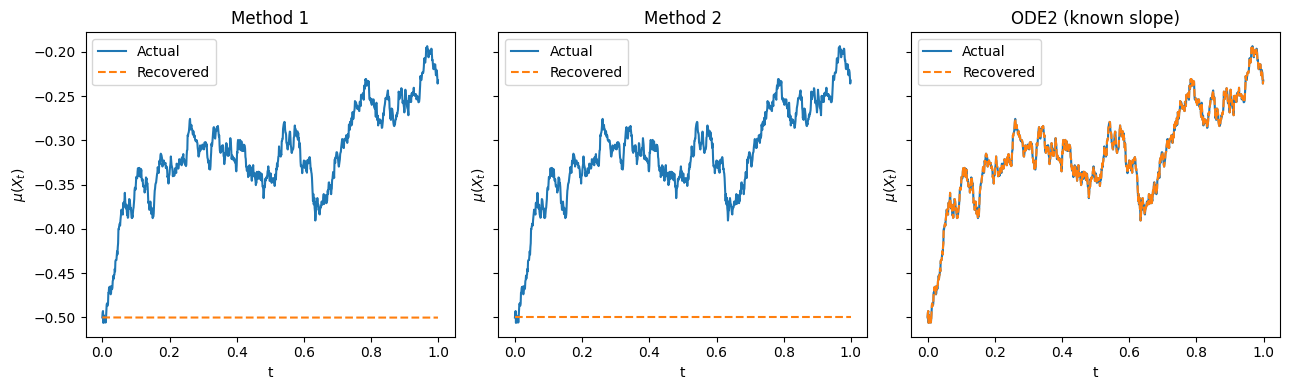

In [10]:
t_ = t[::M]
dt_coarse = M * dt
drift_estimates = {
    'Method 1': mu_pred1,
    'Method 2': mu_pred2,
    'ODE2 (known slope)': mu_ode2_known,
}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (name, estimate) in zip(axes.flat, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.set_ylabel(r'$\mu(X_t)$')
    ax.legend()
    print(f'{name}: drift RMSE = {drift_rmse[name]:.6g}')
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=200)
plt.show()


## Recover $B^P$

Use each drift estimate with the same recovered $B^Q$ and diffusion.
The actual Brownian path is used only for comparison.


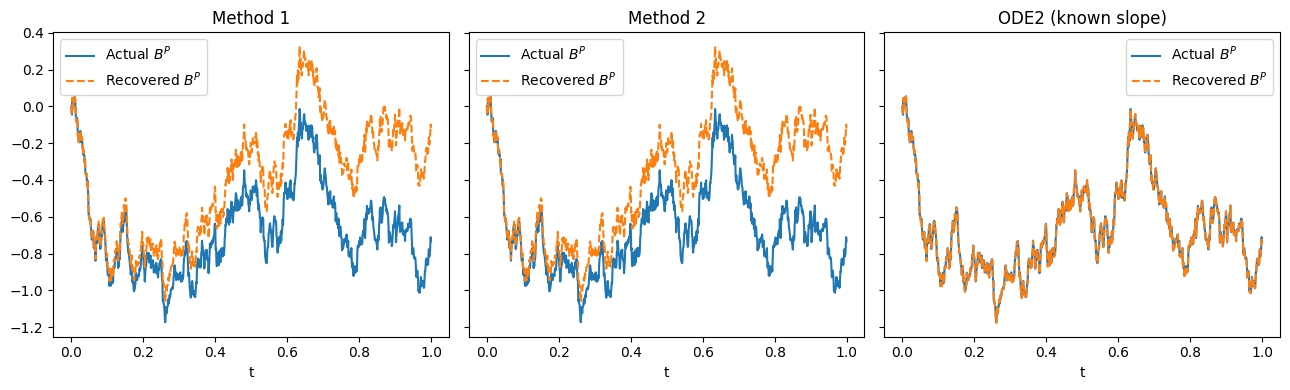

In [11]:
noise_estimates = {
    name: recover_noise(BQ, estimate, sigma_pred, dt_coarse)
    for name, estimate in drift_estimates.items()
}
noise_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, (name, noise) in zip(axes.flat, noise_estimates.items()):
    noise_rmse[name] = float(np.sqrt(np.mean((noise - W)**2)))
    ax.plot(t_, W, label=r'Actual $B^P$')
    ax.plot(t_, noise, '--', label=r'Recovered $B^P$')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
fig.tight_layout()
fig.savefig('noise_comparison.png', dpi=200)
plt.show()


## SSISDE

Fit the same degree-5 libraries and seven-fold time-series selection for every
recovered noise path. A small increment error is not independent evidence of
drift recovery, because the noise was constructed using an estimated drift.


Method 1
MSE: 8.965e-17
μ(X) = -0.50031 + 0.000313807*X
σ(X) = 0.299025 + -1.72459e-07*X
[CV best] alpha=0.000873, l1_ratio (rho)=0.40


Method 2
MSE: 3.194e-32
μ(X) = -0.5
σ(X) = 0.299025
[CV best] alpha=0.000873, l1_ratio (rho)=0.40


ODE2 (known slope)
MSE: 3.185e-32
μ(X) = -0.5*X
σ(X) = 0.299025
[CV best] alpha=0.000873, l1_ratio (rho)=0.30


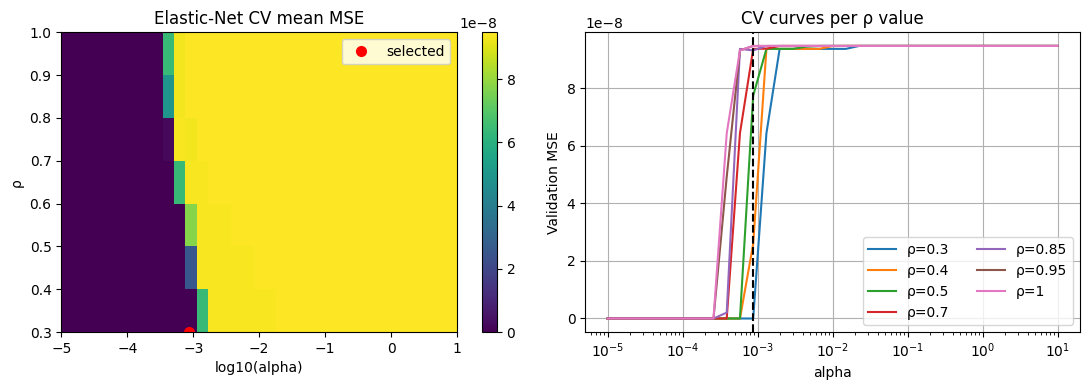

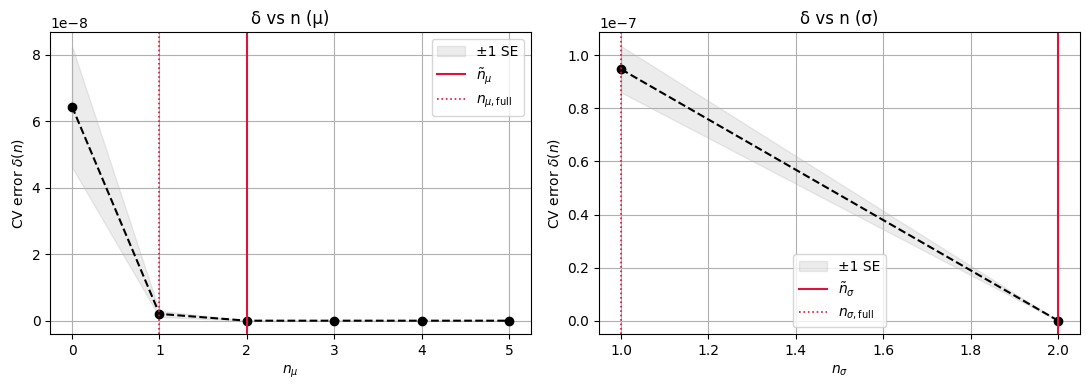

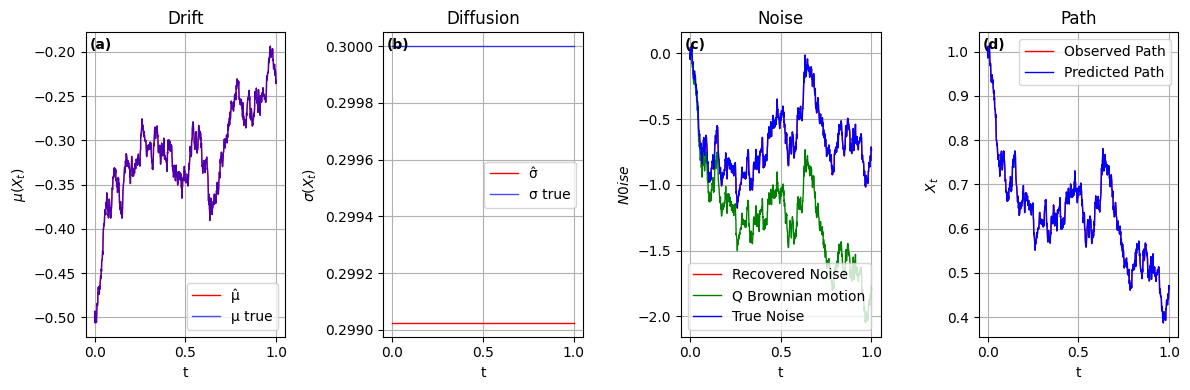

In [12]:
%run -i ../../models/stochastic_sindy.py

identifiers = {}
method_results = {}
with threadpool_limits(limits=1):
    for name, noise in noise_estimates.items():
        identifier = StochSINDy(
            mu_deg=5, si_deg=5, pen='elasticnet', use_cv=True, k=7,
            alphas=np.geomspace(1e-5, 1e1, 35),
            rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0], use_1se=True,
        )
        identifier.fit(S, noise, dt_coarse)
        identifiers[name] = identifier
        method_results[name] = {
            'drift_rmse': drift_rmse[name],
            'noise_rmse': noise_rmse[name],
            'noise_increment_rmse': float(np.sqrt(np.mean((np.diff(noise) - np.diff(W))**2))),
            'ssisde_increment_mse': identifier.mse,
            'ssisde_drift_rmse': float(np.sqrt(np.mean((identifier.mu(S) - mu_exact)**2))),
            'ssisde_diffusion_rmse': float(np.sqrt(np.mean((identifier.si(S) - sigma_exact)**2))),
            'mu': identifier._fmt_poly(identifier.mu_c),
            'sigma': identifier._fmt_poly(identifier.si_c),
            'alpha': identifier.best_a,
            'rho': identifier.best_r,
        }
        print(name)
        identifier.show()

primary_method = 'ODE2 (known slope)'
identifier = identifiers[primary_method]
BP = noise_estimates[primary_method]
model = 'ou_ode2_known'
identifier.plot_cv()
identifier.plot_size(count_bias=True)
identifier.plot_results(S, BP, BQ, W, mu_true=mu_exact, si_true=sigma_exact)


## Fit with the OU library

As a separate comparison, use $\Theta_\mu=\{1,X\}$ and $\Theta_\sigma=\{1\}$.
This supplies the known OU functional form, but not its coefficients.
Use ODE2 with the supplied initial slope.


In [13]:
ou_identifier = StochSINDy(
    mu_deg=1, si_deg=0, pen='elasticnet', use_cv=True, k=7,
    alphas=np.geomspace(1e-8, 1e-2, 35),
    rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0], use_1se=True,
)
with threadpool_limits(limits=1):
    ou_identifier.fit(S, noise_estimates['ODE2 (known slope)'], dt_coarse)
ou_identifier.show()
ou_fit = {
    'mu': ou_identifier._fmt_poly(ou_identifier.mu_c),
    'sigma': ou_identifier._fmt_poly(ou_identifier.si_c),
    'kappa': float(-ou_identifier.mu_c[1]),
    'theta': float(-ou_identifier.mu_c[0] / ou_identifier.mu_c[1]),
    'drift_rmse': float(np.sqrt(np.mean((ou_identifier.mu(S) - mu_exact)**2))),
    'diffusion_rmse': float(np.sqrt(np.mean((ou_identifier.si(S) - sigma_exact)**2))),
    'increment_mse': ou_identifier.mse,
}
print(f"Estimated kappa = {ou_fit['kappa']:.6g}; theta = {ou_fit['theta']:.6g}")


MSE: 3.184e-32
μ(X) = -0.5*X
σ(X) = 0.299025
[CV best] alpha=0.000873, l1_ratio (rho)=0.30
Estimated kappa = 0.5; theta = 0


In [14]:
results = {
    'experiment': 'OU',
    'seed': seed, 'samples': N, 'T': T,
    'kappa': kappa, 'theta': theta, 'sigma': sigm, 'X0': S0,
    'supplied_initial_drift': mu_0,
    'reference_slope': -kappa,
    'state_range': [float(S_.min()), float(S_.max())],
    'sigma_settings': sigma_settings,
    'sigma_squared_equation': sigma_equation,
    'sigma_rmse': sigma_rmse,
    'primary_method': primary_method,
    'methods': method_results,
    'ou_library': ou_fit,
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2))
np.savez(RESULTS / 'paths.npz', t=t_, S=S, W=W, BQ=BQ, mu_exact=mu_exact,
         sigma_exact=sigma_exact, sigma_pred=sigma_pred,
         mu_ode2_known=mu_ode2_known, BP=BP)
print(f"{'Method':26} {'Drift RMSE':>12} {'Noise RMSE':>12}")
for name, row in method_results.items():
    print(f"{name:26} {row['drift_rmse']:12.6g} {row['noise_rmse']:12.6g}")


Method                       Drift RMSE   Noise RMSE
Method 1                       0.192703     0.320246
Method 2                       0.192586     0.320049
ODE2 (known slope)                    0   0.00205747


## Results

The diffusion estimate is $\hat\sigma=0.299025$, compared with $0.3$.
ODE2 uses the supplied initial slope $-0.5$ and recovers the drift $\mu(X)=-0.5X$.
Both the general SSISDE library and the OU library are evaluated with this noise path.

| Method | Drift RMSE | Brownian path RMSE |
|---|---:|---:|
| Method 1 | 0.192703 | 0.320246 |
| Method 2 | 0.192586 | 0.320049 |
| ODE2, known slope | 0.000000 | 0.002057 |

The ODE2 result is conditional on the supplied slope and does not independently
identify the mean-reversion rate. All methods use the known initial drift.
For constant diffusion, Method 2 makes both drift-equation coefficients zero
and therefore returns a constant drift. Method 1 also stays nearly constant in
this run. A small SSISDE increment error does not imply equally small error
against the actual drift or noise.
